# Q2. Sustainability

We measure the carbon footprint of the baseline classifier from Q1 with the Software Carbon Intensity (SCI) specification of the Green Software Foundation (ISO/IEC 21031):

SCI = ((E * I) + M) / R

* E: energy used by the software (kWh), measured with CodeCarbon
* I: carbon intensity of the electricity grid (gCO2eq/kWh)
* M: embodied emissions of the hardware, i.e. the share of the laptop's manufacturing footprint used by the run (gCO2eq)
* R: functional unit

Two boundaries, as in the SCI for AI specification:
* Provider boundary = training, R = one training run
* Consumer boundary = inference on the test set, R = 1,000 predictions

Each stage is repeated 100 times and the measurements are averaged, because a single run takes well under a second.

Note: the energy values depend on the machine. The numbers in the report must come from running this notebook on our own laptop.

In [1]:
import os, math, time, shutil, subprocess, warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from codecarbon import OfflineEmissionsTracker

import common as c

warnings.filterwarnings("ignore", category=FutureWarning)

N_LOOPS = 100
df = c.load_data()
train, val, test = c.split_data(df)
X_test, y_test = c.X_y(test)
print("training rows:", len(train), "| test rows (predictions per inference loop):", len(test))

training rows: 18096 | test rows (predictions per inference loop): 6033


## 1. Energy measurement (E)

We use CodeCarbon, a lightweight Python telemetry tool:
* `tracking_mode="process"`: only the energy attributed to our Python process is counted, not the other programs running on the laptop
* `measure_power_secs=1`: power is sampled every second (the default of 15 s is too coarse for runs of a few seconds)
* one warm-up run is done before measuring, so loading libraries and caches is not counted

How CodeCarbon gets the power depends on the hardware: real sensors when available (Intel RAPL on Linux, powermetrics on Mac), otherwise an estimate from the CPU's TDP and its load. The warnings printed below say which method was used; this has to be mentioned in the report.

In [2]:
def measure(stage, n_loops=N_LOOPS):
    stage()  # warm-up, not measured
    tracker = OfflineEmissionsTracker(
        country_iso_code="BEL",
        measure_power_secs=1,
        tracking_mode="process",
        log_level="warning",
        save_to_file=False,
    )
    tracker.start()
    t0 = time.perf_counter()
    for _ in range(n_loops):
        stage()
    duration = time.perf_counter() - t0
    tracker.stop()
    d = tracker.final_emissions_data
    return {
        "loops": n_loops,
        "duration_s": duration,
        "energy_kwh": d.energy_consumed,
        "cpu_kwh": d.cpu_energy,
        "ram_kwh": d.ram_energy,
        "gpu_kwh": d.gpu_energy,
        "cpu_power_w": d.cpu_power,
        "ram_power_w": d.ram_power,
        "cpu_model": d.cpu_model,
    }

# Training (provider boundary): fit the classifier from scratch
m_train = measure(lambda: c.train_classifier(train))

# Inference (consumer boundary): predict the whole test set
clf = c.train_classifier(train)
m_infer = measure(lambda: clf.predict(X_test))

[codecarbon INFO @ 14:27:17] offline tracker init


[codecarbon WARNING @ 14:27:17] Multiple instances of codecarbon are allowed to run at the same time.


[codecarbon WARNING @ 14:27:37] Multiple instances of codecarbon are allowed to run at the same time.


In [3]:
measures = pd.DataFrame([m_train, m_infer], index=["training", "inference"])
measures["s_per_loop"] = measures["duration_s"] / measures["loops"]
measures["kwh_per_loop"] = measures["energy_kwh"] / measures["loops"]
print("CPU:", m_train["cpu_model"])
measures[["loops", "duration_s", "s_per_loop", "energy_kwh", "kwh_per_loop",
          "cpu_kwh", "ram_kwh", "gpu_kwh", "cpu_power_w", "ram_power_w"]]

CPU: 12th Gen Intel(R) Core(TM) i7-12650H


,loops,duration_s,s_per_loop,energy_kwh,kwh_per_loop,cpu_kwh,ram_kwh,gpu_kwh,cpu_power_w,ram_power_w
training,100,15.624416,0.156244,0.000305,3.047171e-06,0.000088,0.000043,0.000174,18.918505,10.0
inference,100,1.089840,0.010898,0.000017,1.706156e-07,0.000004,0.000003,0.000010,13.336260,10.0


## 2. Assumptions for I, M and R

| Parameter | Value | Source / justification |
|---|---|---|
| I (grid intensity, Belgium) | 181.7 gCO2eq/kWh | Electricity Maps, Grid Review 2025 Belgium: 2025 annual mean, flow-traced (includes imports). Location-based value as required by SCI. |
| TE (total embodied emissions of the laptop) | 308 kgCO2eq | No report exists for our exact laptop, so we use a comparable gaming laptop: Dell G15 5535 product carbon footprint (mean 346 kgCO2eq, of which manufacturing 82.8%, transport 5.4%, end of life 0.7%; the use phase is excluded because it is already counted in E). |
| EL (expected lifespan) | 4 years | Same Dell report. |
| RS (resource share) | 1 | The whole laptop is reserved for the run, nothing else is allocated to it. |
| TR (time reserved) | measured duration of the run | From the measurements above. |
| PUE | 1 for the laptop | No data-centre overhead for a personal laptop. |
| R training | 1 training run | Natural unit of the provider side: one model produced. |
| R inference | 1,000 predictions | Unit suggested by the assignment; per-prediction values would be unreadably small. |

Embodied emissions for one run: M = TE * (TR / EL) * RS.

In [4]:
I_BE = 181.7                      # gCO2eq/kWh, Belgium 2025 mean
TE_G = 0.889 * 346_000            # gCO2eq, manufacturing + transport + end of life
LIFESPAN_S = 4 * 365 * 24 * 3600  # 4 years in seconds
RS = 1.0

def sci(energy_kwh, duration_s, units, intensity=I_BE, pue=1.0):
    # energy and duration are totals over all loops, units = number of functional units in those loops
    o = energy_kwh * pue * intensity
    m = TE_G * (duration_s / LIFESPAN_S) * RS
    return {"O_g": o, "M_g": m, "SCI_g": (o + m) / units, "share_embodied": m / (o + m)}

units_train = m_train["loops"]                          # training runs
units_infer = m_infer["loops"] * len(test) / 1000       # thousands of predictions

baseline = pd.DataFrame({
    "training (per run)": sci(m_train["energy_kwh"], m_train["duration_s"], units_train),
    "inference (per 1,000 predictions)": sci(m_infer["energy_kwh"], m_infer["duration_s"], units_infer),
}).T
baseline["SCI_mg"] = baseline["SCI_g"] * 1000
print(f"TE = {TE_G/1000:.0f} kgCO2eq, I = {I_BE} gCO2eq/kWh")
baseline[["O_g", "M_g", "SCI_g", "SCI_mg", "share_embodied"]]

TE = 308 kgCO2eq, I = 181.7 gCO2eq/kWh


,O_g,M_g,SCI_g,SCI_mg,share_embodied
training (per run),0.055367,0.038099,0.000935,0.934662,0.407625
"inference (per 1,000 predictions)",0.003100,0.002658,0.000010,0.009543,0.461565


## 3. Carbon-aware simulation

The Carbon Aware SDK needs a WattTime or Electricity Maps account to get real data; without one it only ships a JSON file of random test data, which would make the simulation meaningless. The assignment also allows Impact Framework manifests, so we use those: each scenario is a component of the manifest with its own grid intensity, and the GSF builtin plugins compute the SCI.

Scenarios for the training workload (same measured energy and duration, only I and PUE change):

| Scenario | I (gCO2eq/kWh) | Source |
|---|---|---|
| Belgium, 2025 average (baseline) | 181.7 | Electricity Maps 2025, annual mean |
| Belgium, winter evening peak (18:00) | 232.0 | Electricity Maps 2025, winter hourly profile |
| Belgium, summer midday (12:00) | 104.4 | Electricity Maps 2025, summer hourly profile |
| Belgium, cleanest hour of 2025 | 61.5 | Electricity Maps 2025 record (10 June, 09:00) |
| Belgium, dirtiest hour of 2025 | 376.1 | Electricity Maps 2025 record (8 October, 03:00) |
| Cloud region, Sweden | 21.3 | Electricity Maps 2025, annual mean |
| Cloud region, France | 32.0 | Electricity Maps 2025, annual mean |
| Cloud region, Poland | 676.6 | Electricity Maps 2025, annual mean (high-carbon contrast) |

Assumptions for the cloud scenarios: PUE of 1.1 (order of magnitude reported by large cloud providers), and the same energy and embodied emissions as on the laptop (we do not have the hardware data of a cloud server). Network transfer of the data is not counted.

In [5]:
scenarios = pd.DataFrame([
    ("be-average",        "Belgium, 2025 average (baseline)", 181.7, 1.0, "time"),
    ("be-winter-peak",    "Belgium, winter peak 18:00",       232.0, 1.0, "time"),
    ("be-summer-midday",  "Belgium, summer midday 12:00",     104.4, 1.0, "time"),
    ("be-cleanest-hour",  "Belgium, cleanest hour 2025",       61.5, 1.0, "time"),
    ("be-dirtiest-hour",  "Belgium, dirtiest hour 2025",      376.1, 1.0, "time"),
    ("cloud-sweden",      "Cloud, Sweden",                     21.3, 1.1, "location"),
    ("cloud-france",      "Cloud, France",                     32.0, 1.1, "location"),
    ("cloud-poland",      "Cloud, Poland",                    676.6, 1.1, "location"),
], columns=["id", "scenario", "intensity", "pue", "shift"]).set_index("id")

rows = []
for sid, s in scenarios.iterrows():
    r = sci(m_train["energy_kwh"], m_train["duration_s"], units_train, s.intensity, s.pue)
    rows.append({"id": sid, **r})
sim = scenarios.join(pd.DataFrame(rows).set_index("id"))
sim["SCI_mg"] = sim["SCI_g"] * 1000
sim["O_mg_per_run"] = sim["O_g"] / units_train * 1000
sim["M_mg_per_run"] = sim["M_g"] / units_train * 1000
sim["change_vs_baseline"] = sim["SCI_g"] / sim.loc["be-average", "SCI_g"] - 1
sim[["scenario", "intensity", "pue", "O_mg_per_run", "M_mg_per_run", "SCI_mg", "share_embodied", "change_vs_baseline"]]

,scenario,intensity,pue,O_mg_per_run,M_mg_per_run,SCI_mg,share_embodied,change_vs_baseline
id,,,,,,,,
be-average,"Belgium, 2025 average (baseline)",181.7,1.0,0.553671,0.380991,0.934662,0.407625,0.000000
be-winter-peak,"Belgium, winter peak 18:00",232.0,1.0,0.706944,0.380991,1.087935,0.350197,0.163987
be-summer-midday,"Belgium, summer midday 12:00",104.4,1.0,0.318125,0.380991,0.699116,0.544962,-0.252012
be-cleanest-hour,"Belgium, cleanest hour 2025",61.5,1.0,0.187401,0.380991,0.568392,0.670296,-0.391874
be-dirtiest-hour,"Belgium, dirtiest hour 2025",376.1,1.0,1.146041,0.380991,1.527032,0.249498,0.633780
cloud-sweden,"Cloud, Sweden",21.3,1.1,0.071395,0.380991,0.452387,0.842181,-0.515989
cloud-france,"Cloud, France",32.0,1.1,0.107260,0.380991,0.488252,0.780317,-0.477617
cloud-poland,"Cloud, Poland",676.6,1.1,2.267887,0.380991,2.648879,0.143831,1.834049


### Same computation with the Impact Framework

The notebook writes `sci_manifest.yml` with all scenarios (training) and the inference baseline, then runs it with `if-run`. The pipeline uses only IF builtin plugins:
* `Multiply`: operational carbon = energy * grid intensity
* `SciEmbodied`: embodied carbon = TE * (time / lifespan) * usage ratio
* `Sum`: carbon = operational + embodied
* `Sci`: carbon / functional unit

Requirements: Node.js, then `npm install -g @grnsft/if`. If `if-run` is not installed, the cell only writes the manifest; it can be run later with `if-run -m sci_manifest.yml -o sci_output.yml`.

In [6]:
def if_component(m, units, unit_name, intensity, pue, sci_plugin):
    return {
        "pipeline": {"compute": ["operational-carbon", "embodied-carbon", "total-carbon", sci_plugin]},
        "inputs": [{
            "timestamp": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
            "duration": max(1, math.ceil(m["duration_s"])),  # IF needs an integer number of seconds >= 1
            "time": float(m["duration_s"]),                  # real duration, used by SciEmbodied
            "energy": float(m["energy_kwh"] * pue),
            "grid/carbon-intensity": float(intensity),
            unit_name: float(units),
            "usage-ratio": RS,
        }],
    }

manifest = {
    "name": "adult-classifier-sci",
    "description": "SCI of the Adult income classifier (INFO-H420 project, Q2)",
    "initialize": {"plugins": {
        "operational-carbon": {"method": "Multiply", "path": "builtin", "config": {
            "input-parameters": ["energy", "grid/carbon-intensity"], "output-parameter": "carbon-operational"}},
        "embodied-carbon": {"method": "SciEmbodied", "path": "builtin", "config": {
            "baseline-emissions": float(TE_G), "lifespan": LIFESPAN_S}},
        "total-carbon": {"method": "Sum", "path": "builtin", "config": {
            "input-parameters": ["carbon-operational", "embodied-carbon"], "output-parameter": "carbon"}},
        "sci-training": {"method": "Sci", "path": "builtin", "config": {"functional-unit": "training-runs"}},
        "sci-inference": {"method": "Sci", "path": "builtin", "config": {"functional-unit": "thousand-predictions"}},
    }},
    "tree": {"children": {
        "training": {"children": {
            sid: if_component(m_train, units_train, "training-runs", s.intensity, s.pue, "sci-training")
            for sid, s in scenarios.iterrows()
        }},
        "inference": {"children": {
            "be-average": if_component(m_infer, units_infer, "thousand-predictions", I_BE, 1.0, "sci-inference")
        }},
    }},
}
with open("sci_manifest.yml", "w") as f:
    yaml.safe_dump(manifest, f, sort_keys=False)
print("written: sci_manifest.yml")

written: sci_manifest.yml


In [7]:
if_run = shutil.which("if-run")
if if_run is None:
    print("if-run not found: install Node.js and run `npm install -g @grnsft/if`, then rerun this cell.")
    if_results = None
else:
    cmd = [if_run, "-m", "sci_manifest.yml", "-o", "sci_output"]
    p = subprocess.run(cmd, capture_output=True, text=True, shell=(os.name == "nt"))
    if p.returncode != 0:
        print(p.stdout[-2000:], p.stderr[-2000:])
        if_results = None
    else:
        with open("sci_output.yaml") as f:
            out = yaml.safe_load(f)
        rows = []
        for stage, node in out["tree"]["children"].items():
            for sid, comp in node["children"].items():
                o = comp["outputs"][0]
                rows.append({"stage": stage, "id": sid,
                             "IF carbon-operational (g)": o["carbon-operational"],
                             "IF embodied-carbon (g)": o["embodied-carbon"],
                             "IF SCI (mg per unit)": o["sci"] * 1000})
        if_results = pd.DataFrame(rows)
        if_results["Python SCI (mg per unit)"] = [
            sim.loc[r.id, "SCI_mg"] if r.stage == "training" else baseline.loc["inference (per 1,000 predictions)", "SCI_mg"]
            for r in if_results.itertuples()
        ]
if_results

,stage,id,IF carbon-operational (g),IF embodied-carbon (g),IF SCI (mg per unit),Python SCI (mg per unit)
0,training,be-average,0.055367,0.038099,0.934662,0.934662
1,training,be-winter-peak,0.070694,0.038099,1.087935,1.087935
2,training,be-summer-midday,0.031812,0.038099,0.699116,0.699116
3,training,be-cleanest-hour,0.018740,0.038099,0.568392,0.568392
4,training,be-dirtiest-hour,0.114604,0.038099,1.527032,1.527032
5,training,cloud-sweden,0.007140,0.038099,0.452387,0.452387
6,training,cloud-france,0.010726,0.038099,0.488252,0.488252
7,training,cloud-poland,0.226789,0.038099,2.648879,2.648879
8,inference,be-average,0.003100,0.002658,0.009543,0.009543


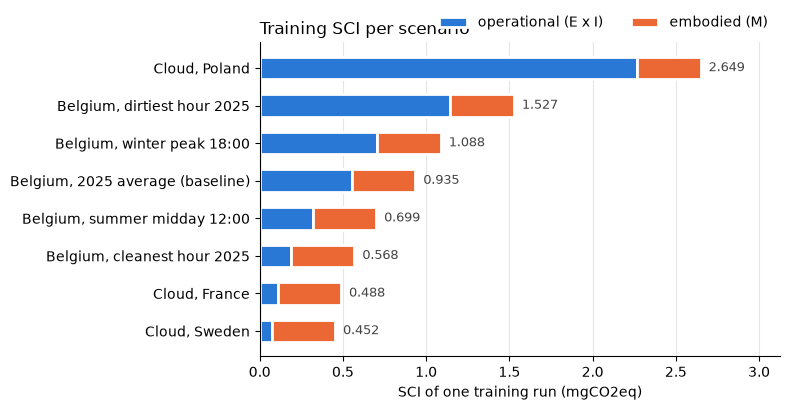

In [8]:
plot = sim.sort_values("SCI_mg")
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(plot))
ax.barh(y, plot["O_mg_per_run"], height=0.6, color="#2a78d6", label="operational (E x I)", edgecolor="white", linewidth=2)
ax.barh(y, plot["M_mg_per_run"], left=plot["O_mg_per_run"], height=0.6, color="#eb6834", label="embodied (M)", edgecolor="white", linewidth=2)
for yi, total in zip(y, plot["SCI_mg"]):
    ax.text(total, yi, f"  {total:.3f}", va="center", fontsize=9, color="#444")
ax.set_yticks(y, plot["scenario"])
ax.set_xlabel("SCI of one training run (mgCO2eq)")
ax.set_title("Training SCI per scenario", loc="left")
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.set_xlim(0, plot["SCI_mg"].max() * 1.18)
plt.tight_layout()
plt.savefig("q2_sci_scenarios.png", dpi=200)
plt.show()

## 4. Discussion: trade-offs of carbon-aware scheduling

* **Only the operational part moves.** Shifting in time or space changes I, so it only reduces E * I. The embodied part M stays the same, so the possible gain is bounded by the operational share of the SCI (see `share_embodied` in the tables). The cleaner the grid, the larger the share of M: on the Swedish or French grid almost all the remaining footprint is embodied, so further reductions would come from using the hardware longer or sharing it better, not from scheduling.
* **Time shifting in Belgium** is free in terms of infrastructure but costs time: the job has to wait for a cleaner hour (midday with solar in spring and summer, versus evening peaks). This is fine for flexible batch jobs such as periodic retraining, not for work that must be done immediately. Hourly averages also hide variation from day to day, so a real scheduler needs forecasts (what the Carbon Aware SDK provides with WattTime or Electricity Maps data).
* **Location shifting** gives the largest reduction on paper but adds costs that the SCI score here does not include: moving the data (network energy), the cloud provider's overhead (PUE), latency, price, and legal constraints on where personal data such as census records may be processed (GDPR). Choosing a bad region (Poland) makes things much worse, so the choice of region matters more than the choice of hour.
* **Scale.** One training run of this model costs a fraction of a milligram of CO2eq. Carbon-aware scheduling is therefore not worth extra complexity for this project, but the same reasoning matters for large or frequently repeated workloads (hyperparameter searches, retraining pipelines, large models), where totals become significant.
* **Uncertainty.** E comes from CodeCarbon, which may estimate CPU and RAM power instead of reading sensors; I values are averages, not marginal emissions; TE comes from a comparable laptop, not ours. The ranking between scenarios is robust to these uncertainties, the absolute values much less.

## 5. Summary for the report

In [9]:
b = baseline
best = sim["SCI_mg"].idxmin(); worst = sim["SCI_mg"].idxmax()
print(f"Training: {m_train['duration_s']/N_LOOPS:.3f} s and {m_train['energy_kwh']/N_LOOPS:.2e} kWh per run (average of {N_LOOPS} runs).")
print(f"Inference: {m_infer['duration_s']/N_LOOPS:.4f} s and {m_infer['energy_kwh']/N_LOOPS:.2e} kWh per pass over {len(test)} test rows.")
print(f"SCI training (Belgium average): {b.iloc[0]['SCI_mg']:.4f} mgCO2eq per training run, embodied share {b.iloc[0]['share_embodied']:.0%}.")
print(f"SCI inference (Belgium average): {b.iloc[1]['SCI_mg']:.4f} mgCO2eq per 1,000 predictions, embodied share {b.iloc[1]['share_embodied']:.0%}.")
print(f"Best scenario: {sim.loc[best, 'scenario']} ({sim.loc[best, 'change_vs_baseline']:+.0%} vs baseline).")
print(f"Worst scenario: {sim.loc[worst, 'scenario']} ({sim.loc[worst, 'change_vs_baseline']:+.0%} vs baseline).")
print(f"Time shifting in Belgium (summer midday vs winter peak): "
      f"{sim.loc['be-summer-midday', 'SCI_mg']:.4f} vs {sim.loc['be-winter-peak', 'SCI_mg']:.4f} mgCO2eq per run.")

Training: 0.156 s and 3.05e-06 kWh per run (average of 100 runs).
Inference: 0.0109 s and 1.71e-07 kWh per pass over 6033 test rows.
SCI training (Belgium average): 0.9347 mgCO2eq per training run, embodied share 41%.
SCI inference (Belgium average): 0.0095 mgCO2eq per 1,000 predictions, embodied share 46%.
Best scenario: Cloud, Sweden (-52% vs baseline).
Worst scenario: Cloud, Poland (+183% vs baseline).
Time shifting in Belgium (summer midday vs winter peak): 0.6991 vs 1.0879 mgCO2eq per run.


**Sources**
* Green Software Foundation, SCI specification (ISO/IEC 21031:2024) and Impact Framework documentation (if.greensoftware.foundation)
* Electricity Maps, Grid Review 2025: Belgium, France, Sweden, Poland (electricitymaps.com/grid-in-review-2025)
* Dell Technologies, Product Carbon Footprint, Dell G15 5535 (July 2025)
* Carbon Aware SDK documentation, data sources (carbon-aware-sdk.greensoftware.foundation)